# Product Review Rating Prediction and Review Clustering

## 1. Introduction

This notebook performs Exploratory Data Analysis (EDA) on the Amazon Product Reviews dataset provided by Datafiniti.

The purpose of this analysis is to understand the structure, quality, and characteristics of the dataset before applying Natural Language Processing and Machine Learning techniques.

The analysis includes:
- Dataset dimensions, columns, and data types.
- Identification of review text and rating attributes.
- Missing value and duplicate analysis.
- Distribution of product ratings.
- Distribution of review lengths.
- Exploration of frequently occurring words in reviews.

**Note:** The original dataset is preserved without modification. All analysis is performed on an in-memory copy of the loaded data.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

# Plot settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

In [6]:
df=pd.read_csv("Consumer_reviews.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
print("Dataset shape:", df.shape)

Dataset shape: (28332, 24)


In [8]:
df.head()

,id,dateAdded,dateUpdated,name,asins,brand,categories,primaryCategories,imageURLs,keys,...,reviews.didPurchase,reviews.doRecommend,reviews.id,reviews.numHelpful,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.username,sourceURLs
0,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,NaN,NaN,NaN,NaN,3,https://www.amazon.com/product-reviews/B00QWO9...,I order 3 of them and one of the item is bad q...,... 3 of them and one of the item is bad quali...,Byger yang,"https://www.barcodable.com/upc/841710106442,ht..."
1,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,NaN,NaN,NaN,NaN,4,https://www.amazon.com/product-reviews/B00QWO9...,Bulk is always the less expensive way to go fo...,... always the less expensive way to go for pr...,ByMG,"https://www.barcodable.com/upc/841710106442,ht..."
2,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,NaN,NaN,NaN,NaN,5,https://www.amazon.com/product-reviews/B00QWO9...,Well they are not Duracell but for the price i...,... are not Duracell but for the price i am ha...,BySharon Lambert,"https://www.barcodable.com/upc/841710106442,ht..."
3,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,NaN,NaN,NaN,NaN,5,https://www.amazon.com/product-reviews/B00QWO9...,Seem to work as well as name brand batteries a...,... as well as name brand batteries at a much ...,Bymark sexson,"https://www.barcodable.com/upc/841710106442,ht..."
4,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,NaN,NaN,NaN,NaN,5,https://www.amazon.com/product-reviews/B00QWO9...,These batteries are very long lasting the pric...,... batteries are very long lasting the price ...,Bylinda,"https://www.barcodable.com/upc/841710106442,ht..."


In [9]:
df.tail()

,id,dateAdded,dateUpdated,name,asins,brand,categories,primaryCategories,imageURLs,keys,...,reviews.didPurchase,reviews.doRecommend,reviews.id,reviews.numHelpful,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.username,sourceURLs
28327,AVqkIhxunnc1JgDc3kg_,2017-03-06T14:59:43Z,2019-02-23T02:49:38Z,"Fire HD 8 Tablet with Alexa, 8 HD Display, 16 ...",B018T075DC,Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablet...",Electronics,https://www.upccodesearch.com/images/barcode/0...,"amazon/b018t075dc,firehd8tabletwithalexa8hddis...",...,NaN,True,NaN,0.0,5,http://reviews.bestbuy.com/3545/5620410/review...,I got 2 of these for my 8 yr old twins. My 11 ...,Xmas gift,Mom2twinsplus1,http://reviews.bestbuy.com/3545/5620410/review...
28328,AVqkIhxunnc1JgDc3kg_,2017-03-06T14:59:43Z,2019-02-23T02:49:38Z,"Fire HD 8 Tablet with Alexa, 8 HD Display, 16 ...",B018T075DC,Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablet...",Electronics,https://www.upccodesearch.com/images/barcode/0...,"amazon/b018t075dc,firehd8tabletwithalexa8hddis...",...,NaN,True,NaN,0.0,4,http://reviews.bestbuy.com/3545/5620410/review...,I bought this for my niece for a Christmas gif...,yes it is a great tablet.,fireman21,http://reviews.bestbuy.com/3545/5620410/review...
28329,AVqkIhxunnc1JgDc3kg_,2017-03-06T14:59:43Z,2019-02-23T02:49:38Z,"Fire HD 8 Tablet with Alexa, 8 HD Display, 16 ...",B018T075DC,Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablet...",Electronics,https://www.upccodesearch.com/images/barcode/0...,"amazon/b018t075dc,firehd8tabletwithalexa8hddis...",...,NaN,True,NaN,0.0,5,http://reviews.bestbuy.com/3545/5620410/review...,"Very nice for light internet browsing, keeping...",You get a lot for the price!,suzannalicious,http://reviews.bestbuy.com/3545/5620410/review...
28330,AVqkIhxunnc1JgDc3kg_,2017-03-06T14:59:43Z,2019-02-23T02:49:38Z,"Fire HD 8 Tablet with Alexa, 8 HD Display, 16 ...",B018T075DC,Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablet...",Electronics,https://www.upccodesearch.com/images/barcode/0...,"amazon/b018t075dc,firehd8tabletwithalexa8hddis...",...,NaN,True,NaN,0.0,5,http://reviews.bestbuy.com/3545/5620410/review...,This Tablet does absolutely everything I want!...,You get the entire World for less than $100!,SandyJ,http://reviews.bestbuy.com/3545/5620410/review...
28331,AVqkIhxunnc1JgDc3kg_,2017-03-06T14:59:43Z,2019-02-23T02:49:38Z,"Fire HD 8 Tablet with Alexa, 8 HD Display, 16 ...",B018T075DC,Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablet...",Electronics,https://www.upccodesearch.com/images/barcode/0...,"amazon/b018t075dc,firehd8tabletwithalexa8hddis...",...,NaN,True,NaN,0.0,4,http://reviews.bestbuy.com/3545/5620410/review...,"At ninety dollars, the expectionations are low...",You get what your paying for,Hung,http://reviews.bestbuy.com/3545/5620410/review...


In [10]:
print(df.columns.tolist())

['id', 'dateAdded', 'dateUpdated', 'name', 'asins', 'brand', 'categories', 'primaryCategories', 'imageURLs', 'keys', 'manufacturer', 'manufacturerNumber', 'reviews.date', 'reviews.dateSeen', 'reviews.didPurchase', 'reviews.doRecommend', 'reviews.id', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.username', 'sourceURLs']


In [11]:
#Checking for data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28332 entries, 0 to 28331
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   28332 non-null  object 
 1   dateAdded            28332 non-null  object 
 2   dateUpdated          28332 non-null  object 
 3   name                 28332 non-null  object 
 4   asins                28332 non-null  object 
 5   brand                28332 non-null  object 
 6   categories           28332 non-null  object 
 7   primaryCategories    28332 non-null  object 
 8   imageURLs            28332 non-null  object 
 9   keys                 28332 non-null  object 
 10  manufacturer         28332 non-null  object 
 11  manufacturerNumber   28332 non-null  object 
 12  reviews.date         28332 non-null  object 
 13  reviews.dateSeen     28332 non-null  object 
 14  reviews.didPurchase  9 non-null      object 
 15  reviews.doRecommend  16086 non-null 

In [12]:
#Statistical Summary
df.describe(include='all')

,id,dateAdded,dateUpdated,name,asins,brand,categories,primaryCategories,imageURLs,keys,...,reviews.didPurchase,reviews.doRecommend,reviews.id,reviews.numHelpful,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.username,sourceURLs
count,28332,28332,28332,28332,28332,28332,28332,28332,28332,28332,...,9,16086,4.100000e+01,16115.000000,28332.000000,28332,28332,28332,28327,28332
unique,65,55,52,65,65,3,60,9,65,65,...,2,2,NaN,NaN,NaN,9906,18168,10441,16268,65
top,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazon,"AA,AAA,Health,Electronics,Health & Household,C...",Electronics,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,True,True,NaN,NaN,NaN,https://www.amazon.com/product-reviews/B00QWO9...,good,Five Stars,ByAmazon Customer,"https://www.barcodable.com/upc/841710106442,ht..."
freq,8343,8343,8343,8343,8343,16153,8343,13995,8343,8343,...,8,15353,NaN,NaN,NaN,12071,60,3937,889,8343
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.840066e+08,0.529321,4.514048,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,2.337036e+07,9.345017,0.934957,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.116244e+08,0.000000,1.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.843344e+08,0.000000,4.000000,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.885078e+08,0.000000,5.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.988160e+08,0.000000,5.000000,NaN,NaN,NaN,NaN,NaN


In [13]:
review_col = 'reviews.text'
rating_col = 'reviews.rating'

df[[review_col, rating_col]].head()

,reviews.text,reviews.rating
0,I order 3 of them and one of the item is bad q...,3
1,Bulk is always the less expensive way to go fo...,4
2,Well they are not Duracell but for the price i...,5
3,Seem to work as well as name brand batteries a...,5
4,These batteries are very long lasting the pric...,5


In [14]:
#Counting the missing values
df.isnull().sum()

id                         0
dateAdded                  0
dateUpdated                0
name                       0
asins                      0
brand                      0
categories                 0
primaryCategories          0
imageURLs                  0
keys                       0
manufacturer               0
manufacturerNumber         0
reviews.date               0
reviews.dateSeen           0
reviews.didPurchase    28323
reviews.doRecommend    12246
reviews.id             28291
reviews.numHelpful     12217
reviews.rating             0
reviews.sourceURLs         0
reviews.text               0
reviews.title              0
reviews.username           5
sourceURLs                 0
dtype: int64

In [15]:
#Calculating percentage of missing values
null_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})

null_summary = null_summary.sort_values(
    by='Missing Values',
    ascending=False
)

display(null_summary)

,Missing Values,Percentage
reviews.didPurchase,28323,99.968234
reviews.id,28291,99.855287
reviews.doRecommend,12246,43.223211
reviews.numHelpful,12217,43.120853
reviews.username,5,0.017648
id,0,0.000000
dateUpdated,0,0.000000
dateAdded,0,0.000000
primaryCategories,0,0.000000
categories,0,0.000000


In [16]:
#Checking missing values in important columns
print("Missing review texts:", df[review_col].isnull().sum())
print("Missing ratings:", df[rating_col].isnull().sum())

Missing review texts: 0
Missing ratings: 0


In [17]:
# Check for empty or whitespace-only review texts
empty_text_mask = (df['reviews.text'].isna() | (df['reviews.text'].astype(str).str.strip() == ''))
empty_text_count = empty_text_mask.sum()

print("Empty or whitespace-only review texts:", empty_text_count)

Empty or whitespace-only review texts: 0


In [18]:
#Find the columns to drop
threshold = 50
columns_to_drop = null_summary[null_summary['Percentage'] > threshold].index

print("Columns to remove:")
print(columns_to_drop)

Columns to remove:
Index(['reviews.didPurchase', 'reviews.id'], dtype='object')


In [19]:
#Creating a cleaned dataset
df_cleaned = df.drop(columns=columns_to_drop)

print("Original shape:", df.shape)
print("Cleaned shape:", df_cleaned.shape)

Original shape: (28332, 24)
Cleaned shape: (28332, 22)


In [20]:
print("Remaining columns:")
print(df_cleaned.columns.tolist())

print("\nMissing values after removing columns:")
print(df_cleaned.isnull().sum())

Remaining columns:
['id', 'dateAdded', 'dateUpdated', 'name', 'asins', 'brand', 'categories', 'primaryCategories', 'imageURLs', 'keys', 'manufacturer', 'manufacturerNumber', 'reviews.date', 'reviews.dateSeen', 'reviews.doRecommend', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.username', 'sourceURLs']

Missing values after removing columns:
id                         0
dateAdded                  0
dateUpdated                0
name                       0
asins                      0
brand                      0
categories                 0
primaryCategories          0
imageURLs                  0
keys                       0
manufacturer               0
manufacturerNumber         0
reviews.date               0
reviews.dateSeen           0
reviews.doRecommend    12246
reviews.numHelpful     12217
reviews.rating             0
reviews.sourceURLs         0
reviews.text               0
reviews.title              0
reviews.username  

In [21]:
#Check for duplicate rows
print("Exact duplicate rows:", df_cleaned.duplicated().sum())

Exact duplicate rows: 0


In [22]:
print("Duplicate review texts:", df_cleaned[review_col].duplicated().sum())

Duplicate review texts: 10164


In [23]:
#Checking if identical reviews have different rating
duplicate_groups = df_cleaned.groupby(review_col).agg(
    count=(rating_col, 'size'),
    unique_ratings=(rating_col, 'nunique')
)

conflicting_texts = duplicate_groups[(duplicate_groups['count'] > 1) & (duplicate_groups['unique_ratings'] > 1)]

print("Repeated review groups:", (duplicate_groups['count'] > 1).sum())

print("Repeated review groups with conflicting ratings:",len(conflicting_texts))

Repeated review groups: 7034
Repeated review groups with conflicting ratings: 118


In [24]:
#Rating distribution analysis
rating_counts = df_cleaned[rating_col].value_counts().sort_index()
print(rating_counts)

reviews.rating
1      965
2      616
3     1206
4     5648
5    19897
Name: count, dtype: int64


In [25]:
rating_percentage = (df_cleaned[rating_col].value_counts(normalize=True).sort_index() * 100)
print(rating_percentage)

reviews.rating
1     3.406043
2     2.174220
3     4.256671
4    19.935056
5    70.228011
Name: proportion, dtype: float64


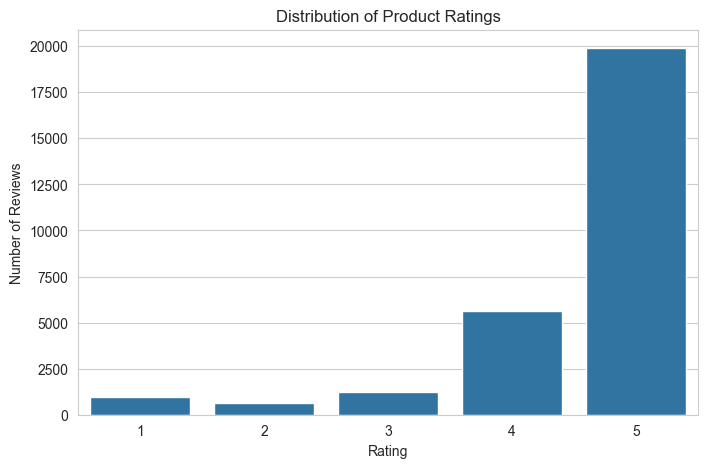

In [26]:
#Visualising the rating distribution
sns.countplot(data=df_cleaned, x=rating_col, order=[1, 2, 3, 4, 5])

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

In [27]:
#Calculating the number of words in each row
review_lengths = df_cleaned[review_col].astype(str).str.split().str.len()

print("Average review length:", review_lengths.mean())
print("Median review length:", review_lengths.median())
print("Shortest review:", review_lengths.min())
print("Longest review:", review_lengths.max())
print("Standard deviation:", review_lengths.std())

Average review length: 25.945009176902442
Median review length: 17.0
Shortest review: 1
Longest review: 1539
Standard deviation: 37.07589915279177


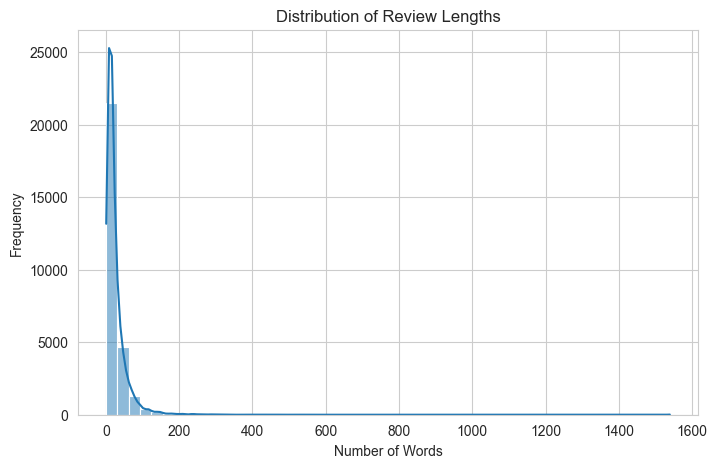

In [28]:
#Review length distribution
sns.histplot(review_lengths, bins=50, kde=True)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

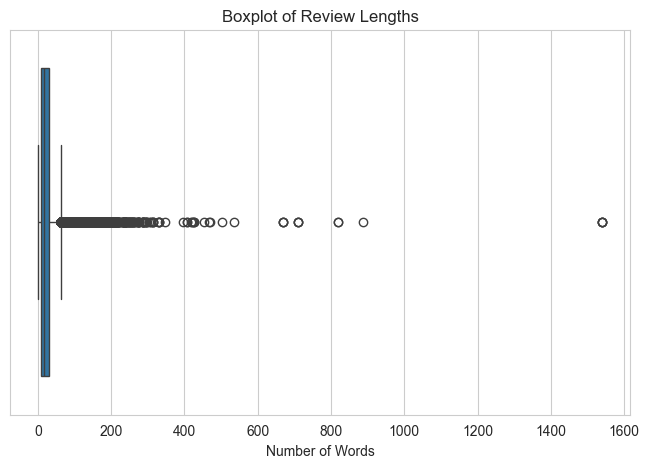

In [29]:
#Checking for extreme review lengths
sns.boxplot(x=review_lengths)

plt.title("Boxplot of Review Lengths")
plt.xlabel("Number of Words")
plt.show()

In [30]:
#Frequent word analysis
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)
all_words = []

for review in df_cleaned[review_col].dropna():
    review = review.lower()
    words = re.findall(r'\b[a-zA-Z]{2,}\b', review)
    words = [word for word in words if word not in stop_words]
    all_words.extend(words)

word_counts = Counter(all_words)

In [31]:
#Displaying frequent words
word_freq_df = pd.DataFrame(
    word_counts.most_common(20),
    columns=['Word', 'Frequency']
)

display(word_freq_df)

,Word,Frequency
0,great,9464
1,batteries,8145
2,tablet,6685
3,good,5906
4,price,5221
5,use,4484
6,amazon,3918
7,love,3549
8,bought,3186
9,easy,2954


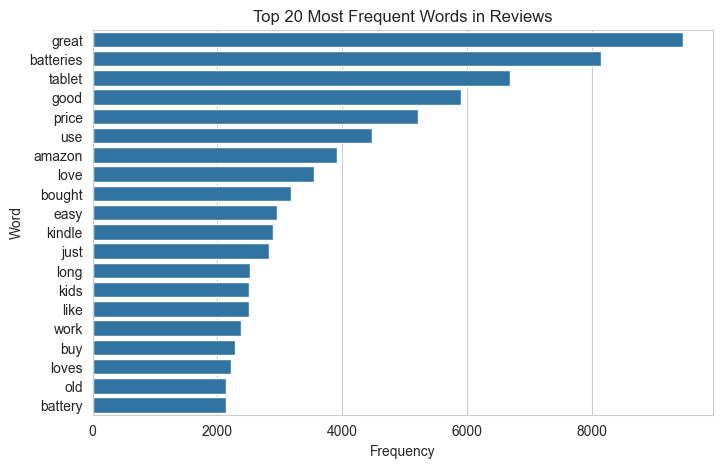

In [32]:
sns.barplot(
    data=word_freq_df,
    x='Frequency',
    y='Word'
)

plt.title("Top 20 Most Frequent Words in Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

In [33]:
# Create a standardized dataset

df_processed = pd.DataFrame({
    'review_text': df['reviews.text'],
    'rating': df['reviews.rating'],
    'review_title': df['reviews.title'],
    'product_name': df['name'],
    'brand': df['brand'],
    'category': df['categories']
})

# Display the standardized dataset
df_processed.head()

,review_text,rating,review_title,product_name,brand,category
0,I order 3 of them and one of the item is bad q...,3,... 3 of them and one of the item is bad quali...,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
1,Bulk is always the less expensive way to go fo...,4,... always the less expensive way to go for pr...,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
2,Well they are not Duracell but for the price i...,5,... are not Duracell but for the price i am ha...,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
3,Seem to work as well as name brand batteries a...,5,... as well as name brand batteries at a much ...,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
4,These batteries are very long lasting the pric...,5,... batteries are very long lasting the price ...,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."


In [34]:
# Record count before filtering
records_before = len(df_processed)

# Identify invalid review texts
empty_text_mask = (
    df_processed['review_text'].isna() |
    (df_processed['review_text'].astype(str).str.strip() == '')
)

# Remove only records with invalid review text
df_processed = df_processed.loc[~empty_text_mask].copy()

# Record count after filtering
records_after = len(df_processed)

# Calculate removed records
records_removed = records_before - records_after

print("Records before processing:", records_before)
print("Records retained:", records_after)
print("Records removed:", records_removed)

Records before processing: 28332
Records retained: 28332
Records removed: 0


In [36]:
import os

# Create processed folder inside preprocessing
os.makedirs('processed', exist_ok=True)

# Save standardized dataset
df_processed.to_csv(
    'processed/standardized_reviews.csv',
    index=False
)

print("Standardized dataset saved successfully!")

Standardized dataset saved successfully!


In [37]:
import pandas as pd
import os

# Verify the processed dataset
file_path = 'processed/standardized_reviews.csv'

if os.path.exists(file_path):
    processed_df = pd.read_csv(file_path)

    print("Saved dataset shape:", processed_df.shape)
    print("Columns:", processed_df.columns.tolist())

    print("\nFirst 5 records:")
    display(processed_df.head())

    # Check for empty or whitespace-only review texts
    empty_text_count = (
        processed_df['review_text'].isna() |
        (processed_df['review_text'].astype(str).str.strip() == '')
    ).sum()

    print("\nEmpty or whitespace-only review texts:", empty_text_count)

    print("\nMissing values in each column:")
    print(processed_df.isnull().sum())

else:
    print("Processed dataset file not found!")

Saved dataset shape: (28332, 6)
Columns: ['review_text', 'rating', 'review_title', 'product_name', 'brand', 'category']

First 5 records:


,review_text,rating,review_title,product_name,brand,category
0,I order 3 of them and one of the item is bad q...,3,... 3 of them and one of the item is bad quali...,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
1,Bulk is always the less expensive way to go fo...,4,... always the less expensive way to go for pr...,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
2,Well they are not Duracell but for the price i...,5,... are not Duracell but for the price i am ha...,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
3,Seem to work as well as name brand batteries a...,5,... as well as name brand batteries at a much ...,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."
4,These batteries are very long lasting the pric...,5,... batteries are very long lasting the price ...,AmazonBasics AAA Performance Alkaline Batterie...,Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C..."



Empty or whitespace-only review texts: 0

Missing values in each column:
review_text     0
rating          0
review_title    0
product_name    0
brand           0
category        0
dtype: int64


# Conclusion

The Datafiniti Amazon Product Consumer Reviews dataset was explored
to understand its structure, quality and characteristics before
applying machine learning techniques.

### Dataset Overview
- Total records: 28,332
- Total columns: 24
- Review text column: reviews.text
- Rating column: reviews.rating
- Rating range: 1 to 5

### Data Quality
- No missing values were found in the review text or rating columns.
- Several metadata columns contained a large percentage of missing values.
- Columns with more than 50% missing values were removed from the
  cleaned DataFrame.
- No exact duplicate rows were found.
- 10,164 repeated review-text occurrences were identified.
- 117 repeated review-text groups had conflicting ratings.

### Rating Distribution
- 1-star reviews: 965
- 2-star reviews: 616
- 3-star reviews: 1,206
- 4-star reviews: 5,648
- 5-star reviews: 19,897

The dataset is imbalanced, with approximately 70.23% of reviews
having a five-star rating.

### Review Length
- Average review length: 25.945009176902442
- Median review length: 17.0
- Shortest review: 1
- Longest review: 1539

### Frequent Words

The 20 most frequently occurring words in the customer reviews were
identified after converting the text to lowercase, removing common
English stopwords, and extracting words using regular expressions.

| Word | Frequency |
|---|---:|
| great | 9,464 |
| batteries | 8,145 |
| tablet | 6,685 |
| good | 5,906 |
| price | 5,221 |
| use | 4,484 |
| amazon | 3,918 |
| love | 3,549 |
| bought | 3,186 |
| easy | 2,954 |
| kindle | 2,886 |
| just | 2,819 |
| long | 2,514 |
| kids | 2,510 |
| like | 2,503 |
| work | 2,370 |
| buy | 2,276 |
| loves | 2,211 |
| old | 2,136 |
| battery | 2,132 |

**Observations:**

- Words such as "great" and "good" occur frequently, indicating
  that many reviews contain positive feedback.
- Product-related terms such as "batteries", "tablet", "kindle"
  and "battery" are common, reflecting the products discussed.
- Words such as "price", "easy" and "work" suggest that customers
  frequently discuss product affordability, ease of use and
  performance.
- The frequent occurrence of positive words may be related to
  the high proportion of five-star ratings in the dataset.

### Overall Conclusion

The Datafiniti Amazon Product Consumer Reviews dataset was explored
to understand its structure, quality and characteristics before
applying machine learning techniques.

The dataset contains 28,332 records and 24 columns. The review text
and rating columns were identified as the most important attributes
for the project.

Several metadata columns contained a large percentage of missing
values. Columns with more than 50% missing values were removed
from a separate cleaned DataFrame, while the original dataset
remained unchanged.

No exact duplicate rows were found. However, 10,164 repeated
review-text occurrences were identified, including 118 groups
of identical review texts associated with conflicting ratings.

The rating distribution was found to be imbalanced, with
approximately 70.23% of reviews having a five-star rating.

Review-length analysis was performed to understand the distribution
of review sizes, and frequent-word analysis provided insights into
commonly discussed products and customer opinions.

Overall, the dataset is suitable for the proposed tasks of
product review rating prediction and review clustering.
However, the rating imbalance and repeated review texts with
conflicting ratings should be considered during model development.